# Lecture 8 Activity – Did MLB's 2023 rules raise stolen bases?

QSS 20 · Modern Statistical Computing · Fall 2026

## The question

Before the 2023 season, Major League Baseball changed three rules at once. A
pitch clock limits the time between pitches. A pitcher may step off the
rubber or throw to a base only twice per batter; a third failed try gives the
runner the next base. The bases grew from 15 to 18 inches on a side, which
shortens the distance between them.

All three changes favor a runner who tries to steal a base. If the rules
worked as designed, runners stole more after 2022. Each team's season totals
measure whether they did, and by how much.

> **Did base runners steal more often after the 2023 rule changes, and by how
> much?**

The MLB Stats API publishes each team's season totals. One request returns
all 30 teams for one season, so eleven requests cover 2015 to 2025.

### The MLB Stats API

Major League Baseball's Stats API, at `statsapi.mlb.com`, serves MLB's game,
player, and team records as JSON, with no key. This activity uses one of its
endpoints, `teams/stats`. Here is that endpoint's entry in the
[MLB-StatsAPI endpoint list](https://github.com/toddrob99/MLB-StatsAPI/wiki/Endpoints):

<img src="../lectures/lec08/images/api-mlb-docs.png" width="560" alt="The entry Endpoint: teams_stats in the volunteer MLB-StatsAPI wiki. URL: https://statsapi.mlb.com/api/{ver}/teams/stats. Required parameters: season + group + stats. All parameters: ver, season, sportIds, group, gameType, stats, order, sortStat, fields, startDate, endDate. Note: use meta('statGroups') to look up valid values for group, and meta('statTypes') for valid values for stats">

This documentation is **unofficial**. PokeAPI, NYC Open Data, and FRED each
document their own API: the organization that runs the server writes the
documentation. MLB's own documentation site asks for a login, so this list
comes from the wiki of MLB-StatsAPI, a Python package that volunteers keep on
GitHub. The wiki says so itself: "This information is provided for reference only, without warranty or guarantee, and is not official documentation provided by MLB. This package and its author are not affiliated with MLB or any MLB team."

MLB has no part in the wiki, and it can change or remove an endpoint without
telling the wiki's authors. Use it to find endpoints and parameters, then check each detail
against what the server returns.

### Reminders

- The row unit you build is **one team in one season**.
- This activity needs `requests`. If `import requests` fails, run
  `conda activate qss20` and then `conda install requests` in a terminal.
- Save each response before you parse it, and pause between requests. MLB's
  [copyright notice](https://gdx.mlb.com/components/copyright.txt) permits
  only individual, non-commercial, non-bulk use, so keep the number of
  requests small.
- If the network fails, skip to Task 3: `data/raw/mlb/` holds the eleven
  responses saved on 2026-10-08.
- In the starter cells, replace each `...` with code.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

pd.set_option('display.max_rows', 12)

# Sharp figures on high-resolution screens, from lecture 6.
%config InlineBackend.figure_format = 'retina'

RAW = Path('../data/raw')
LIVE = Path('../data/live/mlb')
LIVE.mkdir(parents=True, exist_ok=True)

MLB = 'https://statsapi.mlb.com/api/v1'
mlb_url = MLB + '/teams/stats'

# Check: the saved snapshot holds eleven seasons.
sorted(p.name for p in (RAW / 'mlb').glob('teams-hitting-*.json'))

['teams-hitting-2015.json',
 'teams-hitting-2016.json',
 'teams-hitting-2017.json',
 'teams-hitting-2018.json',
 'teams-hitting-2019.json',
 'teams-hitting-2020.json',
 'teams-hitting-2021.json',
 'teams-hitting-2022.json',
 'teams-hitting-2023.json',
 'teams-hitting-2024.json',
 'teams-hitting-2025.json']

## Before the tasks · The Padres' most recent game

Check that the API answers, and that you can read its answers, before you
collect eleven seasons. Three requests find the San Diego Padres' most recent
game and print their batting line from it. Run the three cells; there is
nothing to fill in.

In [2]:
# 1. The teams endpoint lists every major-league team with its id.
res = requests.get(MLB + '/teams', params={'sportId': 1}, timeout=30)
[(t['id'], t['name']) for t in res.json()['teams'] if 'Padres' in t['name']]

[(135, 'San Diego Padres')]

In [3]:
# 2. The schedule endpoint lists one team's games in a season.
# gameType: R is the regular season; F, D, L, W are the postseason rounds.
params = {'sportId': 1, 'teamId': 135, 'season': 2026,
          'gameType': 'R,F,D,L,W'}
res = requests.get(MLB + '/schedule', params=params, timeout=30)
games = [g for day in res.json()['dates'] for g in day['games']
         if g['status']['abstractGameState'] == 'Final']
last = games[-1]
away, home = last['teams']['away'], last['teams']['home']
(last['officialDate'], away['team']['name'], away['score'],
 home['team']['name'], home['score'])

('2026-10-07', 'Milwaukee Brewers', 3, 'San Diego Padres', 1)

In [4]:
# 3. The boxscore endpoint holds each team's statistics for one game.
res = requests.get(f"{MLB}/game/{last['gamePk']}/boxscore", timeout=30)
box = res.json()
side = 'home' if box['teams']['home']['team']['id'] == 135 else 'away'
batting = box['teams'][side]['teamStats']['batting']
{k: batting[k] for k in ['runs', 'hits', 'homeRuns', 'baseOnBalls',
                         'strikeOuts', 'stolenBases']}

{'runs': 1,
 'hits': 3,
 'homeRuns': 1,
 'baseOnBalls': 4,
 'strikeOuts': 9,
 'stolenBases': 0}

The API answered all three requests. Each request used a value from the one
before it: the team id `135`, then the game's id, `gamePk`. The filter on
`'Final'` keeps games that have ended, so a game in progress does not count.
The box score's batting record has a key named `stolenBases`, the statistic
this activity counts.

## Find `stolenBases` in the unofficial documentation

The box score covers one game; the tasks need each team's season totals.
Use the unofficial [MLB-StatsAPI endpoint list](https://github.com/toddrob99/MLB-StatsAPI/wiki/Endpoints) to find
the endpoint and its parameters.

1. Search the page for "stats" and open the entry
   [`teams_stats`](https://github.com/toddrob99/MLB-StatsAPI/wiki/Endpoints#endpoint-teams_stats). It gives the URL,
   `https://statsapi.mlb.com/api/{ver}/teams/stats` (`ver` is `v1`), and the
   required parameters: `season`, `group`, and `stats`.
2. The entry adds a note: look up the valid values of `group` with
   `meta('statGroups')`, and of `stats` with `meta('statTypes')`.
3. The [`meta`](https://github.com/toddrob99/MLB-StatsAPI/wiki/Endpoints#endpoint-meta) entry turns these into URLs:
   `/api/v1/statGroups` and `/api/v1/statTypes`. Its type `baseballStats`
   lists the name of every statistic.

In [5]:
groups = requests.get(MLB + '/statGroups', timeout=30).json()
names = requests.get(MLB + '/baseballStats', timeout=30).json()
([g['displayName'] for g in groups],
 [n['name'] for n in names if 'stolen' in n['name'].lower()])

(['hitting',
  'pitching',
  'fielding',
  'catching',
  'running',
  'game',
  'team',
  'streak'],
 ['stolenBases', 'stolenBasePercentage'])

`group='hitting'` holds a team's batting statistics, `stats='season'` asks
for season totals, and `stolenBases` is the key to look for. `sportIds=1`
keeps the major leagues. Task 1 puts these together.

## Task 1 · One season, one path

Request the 2022 season. Check the status code and the content type before
you parse anything. Then find the path from the parsed response to one team's
`stolenBases`.

How many teams does the response hold, and how many bases did the first team
steal in 2022?

In [6]:
res = requests.get(mlb_url, params={'season': 2022, 'group': 'hitting',
                                    'stats': 'season', 'sportIds': 1},
                   timeout=30)
res.status_code, res.headers['Content-Type']

(200, 'application/json;charset=UTF-8')

In [7]:
data = res.json()
data.keys(), data['stats'][0].keys()

(dict_keys(['stats']),
 dict_keys(['type', 'group', 'totalSplits', 'exemptions', 'splits', 'splitsTiedWithOffset', 'splitsTiedWithLimit']))

In [8]:
splits = data['stats'][0]['splits']
first = splits[0]
len(splits), first['team']['name'], first['stat']['stolenBases']

(30, 'Toronto Blue Jays', 67)

The response is a 200 with JSON. Its path to one team is
`data['stats'][0]['splits'][i]`: a dictionary, a list, a dictionary, then a
list with **30** elements, one per team. The stolen bases sit at
`['stat']['stolenBases']` and the team name at `['team']['name']`. When this
solution ran, the first team listed was the Toronto Blue Jays, with **67**
stolen bases in 2022. The order of the teams can differ between requests.

## Task 2 · Eleven seasons, each saved

Write a loop over the seasons 2015 to 2025. For each season: send the request,
stop if it failed, save `res.text` as `LIVE / f'teams-hitting-{season}.json'`
with `encoding='utf-8'`, print the season and the number of teams, and pause
one second.

How many requests does the loop send? If the request for 2020 failed, what
would your loop do, and what would be on disk?

In [9]:
for season in range(2015, 2026):
    params = {'season': season, 'group': 'hitting', 'stats': 'season',
              'sportIds': 1}
    res = requests.get(mlb_url, params=params, timeout=30)
    res.raise_for_status()
    path = LIVE / f'teams-hitting-{season}.json'
    path.write_text(res.text, encoding='utf-8')
    print(season, len(res.json()['stats'][0]['splits']))
    time.sleep(1)

2015 30


2016 30


2017 30


2018 30


2019 30


...

2021 30


2022 30


2023 30


2024 30


2025 30


The loop sends **11** requests, one per season, and each returns 30 teams. If
the 2020 request failed, `raise_for_status()` would stop the loop at 2020. The
files for 2015 to 2019 would already be on disk, because each response is
saved when it arrives. Nothing from 2020 on would be there. Rerun the loop for
the missing seasons only.

## Task 3 · From saved files to a table

Build a DataFrame `teams` from the **saved snapshot** in `RAW / 'mlb'`, with
one row per team and season and five columns: `season`, `team`, `games`
(`gamesPlayed`), `sb` (`stolenBases`), and `cs` (`caughtStealing`).

Then print three checks. How many rows should `teams` have? Does every season
have 30 teams? Is `sb` a number?

In [10]:
rows = []
for path in sorted((RAW / 'mlb').glob('teams-hitting-*.json')):
    data = json.loads(path.read_text(encoding='utf-8'))
    for split in data['stats'][0]['splits']:
        rows.append({'season': int(split['season']),
                     'team': split['team']['name'],
                     'games': split['stat']['gamesPlayed'],
                     'sb': split['stat']['stolenBases'],
                     'cs': split['stat']['caughtStealing']})
teams = pd.DataFrame(rows)
teams

,season,team,games,sb,cs
0,2015,Detroit Tigers,161,83,51
1,2015,Toronto Blue Jays,162,88,23
2,2015,Kansas City Royals,162,104,34
3,2015,San Francisco Giants,162,93,36
4,2015,Colorado Rockies,162,97,43
...,...,...,...,...,...
325,2025,Texas Rangers,162,134,33
326,2025,Chicago White Sox,162,85,21
327,2025,Pittsburgh Pirates,162,115,36
328,2025,Cleveland Guardians,162,129,34


In [11]:
print('rows:', len(teams))
print('teams per season:', teams.groupby('season').size().unique())
print(teams.dtypes)

rows: 330
teams per season: [30]
season     int64
team      object
games      int64
sb         int64
cs         int64
dtype: object


`teams` has **330 rows**: 11 seasons times 30 teams, and each season has 30
teams. `games`, `sb`, and `cs` are integers: this API writes counts as
JSON numbers. (Rates such as `avg` arrive as text, `'.276'`, so convert those
before arithmetic.)

## Task 4 · ❓ Steals per game

Total stolen bases by season can mislead: the 2020 season was cut to 60 games
per team. Build a table `league` with one row per season and the columns `sb`,
`games`, and `sb_per_game`, the stolen bases per team per game. Draw
`sb_per_game` by season and mark the 2023 rule change.

By how much did `sb_per_game` change from 2022 to 2023? Is 2020 unusual once
you divide by games?

In [12]:
league = teams.groupby('season')[['sb', 'games']].sum()
league = league.assign(sb_per_game=league['sb'] / league['games'])
league.round(3)

,sb,games,sb_per_game
season,,,
2015,2505,4858,0.516
2016,2537,4856,0.522
2017,2527,4860,0.520
2018,2474,4862,0.509
2019,2280,4858,0.469
2020,885,1796,0.493
2021,2213,4858,0.456
2022,2486,4860,0.512
2023,3503,4860,0.721


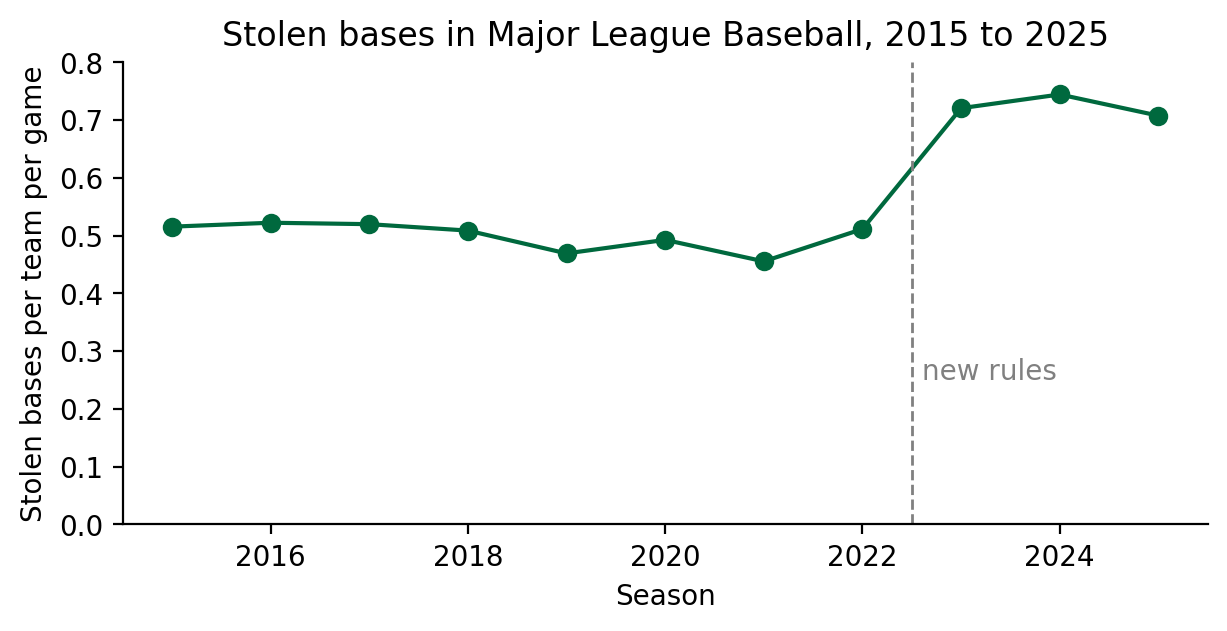

In [13]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(league.index, league['sb_per_game'], marker='o', color='#00693e')
ax.axvline(2022.5, color='grey', ls='--', lw=1)
ax.text(2022.6, 0.25, 'new rules', color='grey')
ax.set(ylim=(0, 0.8), xlabel='Season', ylabel='Stolen bases per team per game',
       title='Stolen bases in Major League Baseball, 2015 to 2025')
ax.spines[['top', 'right']].set_visible(False);

In [14]:
before = league.loc[2022, 'sb_per_game']
after = league.loc[2023, 'sb_per_game']
round(after - before, 3), round(after / before - 1, 3)

(0.209, 0.409)

Steals per team per game rose from **0.512** in 2022 to **0.721** in 2023, an
increase of 0.209, or **41 percent**, and stayed near that level in 2024
(0.745) and 2025 (0.708). From 2015 to 2022 the rate stayed between 0.456 and
0.522.

2020 has the fewest stolen bases in total, 885, but only because it had the
fewest games. Per game, 2020 (0.493) sits between 2019 (0.469) and 2021
(0.456). Compare seasons by steals per game, not by the total.

## Task 5 · What the numbers cannot tell you

Write two or three sentences. Which of the three new rules caused the rise in
stolen bases? What would you need to know to answer that, and what else could
have changed in 2023?

These data cannot say which rule mattered. All three changes began in the
same season, for every team at once, so no team or season isolates one rule.
Answering that would need variation in one rule alone, for example a minor
league that tested the bigger bases before the pitch clock.

Teams also choose how often to try. Some of the rise may come from managers
who decided that steals were now worth the risk, and these totals do not
record that decision. The totals show that stealing rose in 2023 and stayed
high.

## What to take from this

- Find the path to one value in one response before you loop over many.
- Save each response as it arrives, then build the table from the saved files.
- Compare rates, not totals, when the number of games, people, or days
  differs between the groups you compare.